# Student Scholarship Prediction
**Data Mining & Data Warehousing (BTCO14505) - Open Ended Project**

- **Aim:** predict whether a student is *Awarded* (1) or *Rejected* (0) for a scholarship scheme
- **Part 1:** Data pre-processing &nbsp;&nbsp; **Part 2:** Classification (Decision Tree, Naive Bayes, kNN, ID3 from scratch)
- **Target:** `Outcome` &nbsp;&nbsp; **Dataset:** `dataset_combined.xlsx` (245,760 applications, 10 schemes)

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix

PATH = r'C:/Users/meett/OneDrive/Desktop/SCET/SCET_SEM_5/DMDW/OEP/dataset_combined.xlsx'   # <- your file
pd.set_option('display.width', 200)

# ---- chart style (seaborn): one colour per meaning, thin marks, light grid
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'   # fixed order, colour-blind safe
SEQ = sns.blend_palette(['#cde2fb', '#256abf', '#0d366b'], as_cmap=True)    # light -> dark blue (magnitude)
sns.set_theme(style='whitegrid', context='notebook',
              rc={'axes.spines.top': False, 'axes.spines.right': False, 'grid.color': '#e5e4e0',
                  'axes.titleweight': 'bold', 'axes.titlesize': 13, 'figure.dpi': 110})

---
# PART 1: Data Pre-processing

## 1.1 Load and understand the data
Read the Excel file and look at its size, column types and first rows.

In [2]:
df = pd.read_excel(PATH)
print('Rows, Columns :', df.shape)
print('\nColumn types:\n', df.dtypes.to_string())
df.head()

Rows, Columns : (245760, 12)

Column types:
 Name                       object
Education Qualification    object
Gender                     object
Community                  object
Religion                   object
Exservice-men              object
Disability                 object
Sports                     object
Annual-Percentage          object
Income                     object
India                      object
Outcome                     int64


,Name,Education Qualification,Gender,Community,Religion,Exservice-men,Disability,Sports,Annual-Percentage,Income,India,Outcome
0,INSPIRE Scholarship 2022-23 ? Scholarship for ...,Undergraduate,Male,General,Hindu,Yes,Yes,Yes,90-100,Upto 1.5L,In,1
1,INSPIRE Scholarship 2022-23 ? Scholarship for ...,Undergraduate,Male,General,Hindu,Yes,Yes,No,90-100,Upto 1.5L,In,1
2,INSPIRE Scholarship 2022-23 ? Scholarship for ...,Undergraduate,Male,General,Muslim,Yes,Yes,Yes,90-100,Upto 1.5L,In,1
3,INSPIRE Scholarship 2022-23 ? Scholarship for ...,Undergraduate,Male,General,Muslim,Yes,Yes,No,90-100,Upto 1.5L,In,1
4,INSPIRE Scholarship 2022-23 ? Scholarship for ...,Undergraduate,Male,General,Chirstian,Yes,Yes,Yes,90-100,Upto 1.5L,In,1


## 1.2 Data cleaning
Data cleaning: check missing values and duplicates, rename columns, fix spelling mistakes and shorten the scheme names.

In [7]:

print('Missing values  :', int(df.isna().sum().sum()))
print('Duplicate rows  :', int(df.duplicated().sum()))

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

df = df.rename(columns={
    'Education Qualification': 'Education',
    'Exservice-men': 'ExService',
    'Annual-Percentage': 'Percentage'
})

# Fix spelling mistakes
df['Education'] = df['Education'].replace({'Doctrate': 'Doctorate'})
df['Religion'] = df['Religion'].replace({'Chirstian': 'Christian'})

# Shorten scholarship scheme names
SHORT = {
    'INSPIRE Scholarship 2022-23 ? Scholarship for Higher Education (SHE)': 'INSPIRE-SHE',
    'Abdul Kalam Technology Innovation National Fellowship': 'Abdul Kalam Fellowship',
    'AAI Sports Scholarship Scheme in India 2022-23': 'AAI Sports',
    'Glow and lovely Career Foundation Scholarship': 'Glow & Lovely',
    'National Fellowship for Persons with Disabilities': 'NF Disabilities',
    'ONGC Sports Scholarship Scheme 2022-23': 'ONGC Sports',
    'Pragati Scholarship ? AICTE-Scholarship Scheme to Girl Child': 'Pragati (AICTE)',
    'Dr. Ambedkar post matric Scholarship': 'Dr. Ambedkar',
    'Indira Gandhi Scholarship for Single Girl Child UGC Scholarship for PG Programmes': 'Indira Gandhi',
    'National Overseas Scholarship Scheme 2021-22': 'National Overseas'
}

# Support both original and already-renamed columns
if 'Name' in df.columns:
    df['Name'] = df['Name'].replace(SHORT)
    df = df.rename(columns={'Name': 'Scheme'})
elif 'Scheme' in df.columns:
    df['Scheme'] = df['Scheme'].replace(SHORT)
else:
    raise KeyError(f"Neither 'Name' nor 'Scheme' found. Columns: {df.columns.tolist()}")

print('\nSchemes:', df['Scheme'].unique().tolist())


Missing values  : 0
Duplicate rows  : 0

Schemes: ['INSPIRE-SHE', 'Abdul Kalam Fellowship', 'AAI Sports', 'Glow & Lovely', 'NF Disabilities', 'ONGC Sports', 'Pragati (AICTE)', 'Dr. Ambedkar', 'Indira Gandhi', 'National Overseas']


## 1.3 Class balance
Check how many applications are Awarded and Rejected. The classes are imbalanced, so accuracy alone is not enough to judge a model.

Outcome
Rejected    212992
Awarded      32768 

Outcome
Rejected    86.7%
Awarded     13.3%


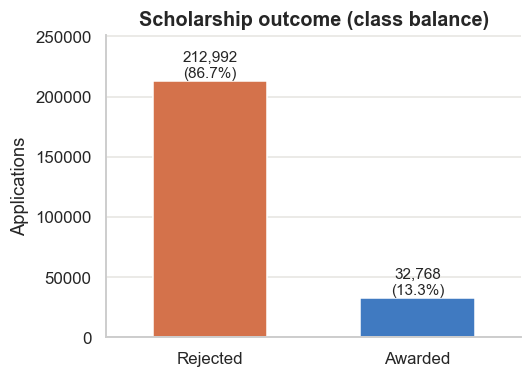

In [8]:
bal = df.Outcome.value_counts().rename({0: 'Rejected', 1: 'Awarded'})
print(bal.to_string(), '\n')
print((bal / len(df) * 100).round(1).astype(str).add('%').to_string())

fig, ax = plt.subplots(figsize=(5, 3.6))
sns.barplot(x=bal.index, y=bal.values, palette=[ORANGE, BLUE], hue=bal.index, legend=False, ax=ax, width=0.55)
for p, v in zip(ax.patches, bal.values):
    ax.annotate(f'{v:,}\n({v/len(df):.1%})', (p.get_x() + p.get_width() / 2, v), ha='center', va='bottom', fontsize=10)
ax.set_title('Scholarship outcome (class balance)'); ax.set_xlabel(''); ax.set_ylabel('Applications')
ax.set_ylim(0, bal.max() * 1.18); plt.tight_layout(); plt.show()

## 1.4 Attribute relevance (chi-square / Cramer's V)
Chi-square test and Cramer's V show how strongly each attribute is related to the Outcome.

            Cramers_V  p_value
India          0.2942      0.0
Scheme         0.2515      0.0
Education      0.1452      0.0
Sports         0.0980      0.0
Gender         0.0674      0.0
Community      0.0558      0.0
Disability     0.0490      0.0
Income         0.0438      0.0
Percentage     0.0318      0.0
Religion       0.0000      1.0
ExService      0.0000      1.0


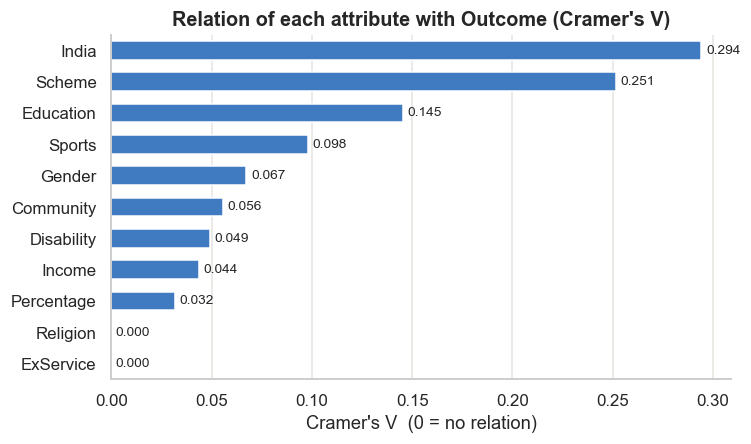

In [9]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(t)
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1))), p

rel = pd.DataFrame({c: cramers_v(df[c], df.Outcome) for c in df.columns if c != 'Outcome'},
                   index=['Cramers_V', 'p_value']).T.sort_values('Cramers_V', ascending=False)
print(rel.round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.barplot(x=rel['Cramers_V'], y=rel.index, color=BLUE, width=0.6, ax=ax)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=3, fontsize=9)
ax.set_title("Relation of each attribute with Outcome (Cramer's V)"); ax.set_xlabel("Cramer's V  (0 = no relation)"); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 1.5 Data visualisation (award rate)
Seaborn charts: award rate (%) for every scheme and every attribute, plus heatmaps.

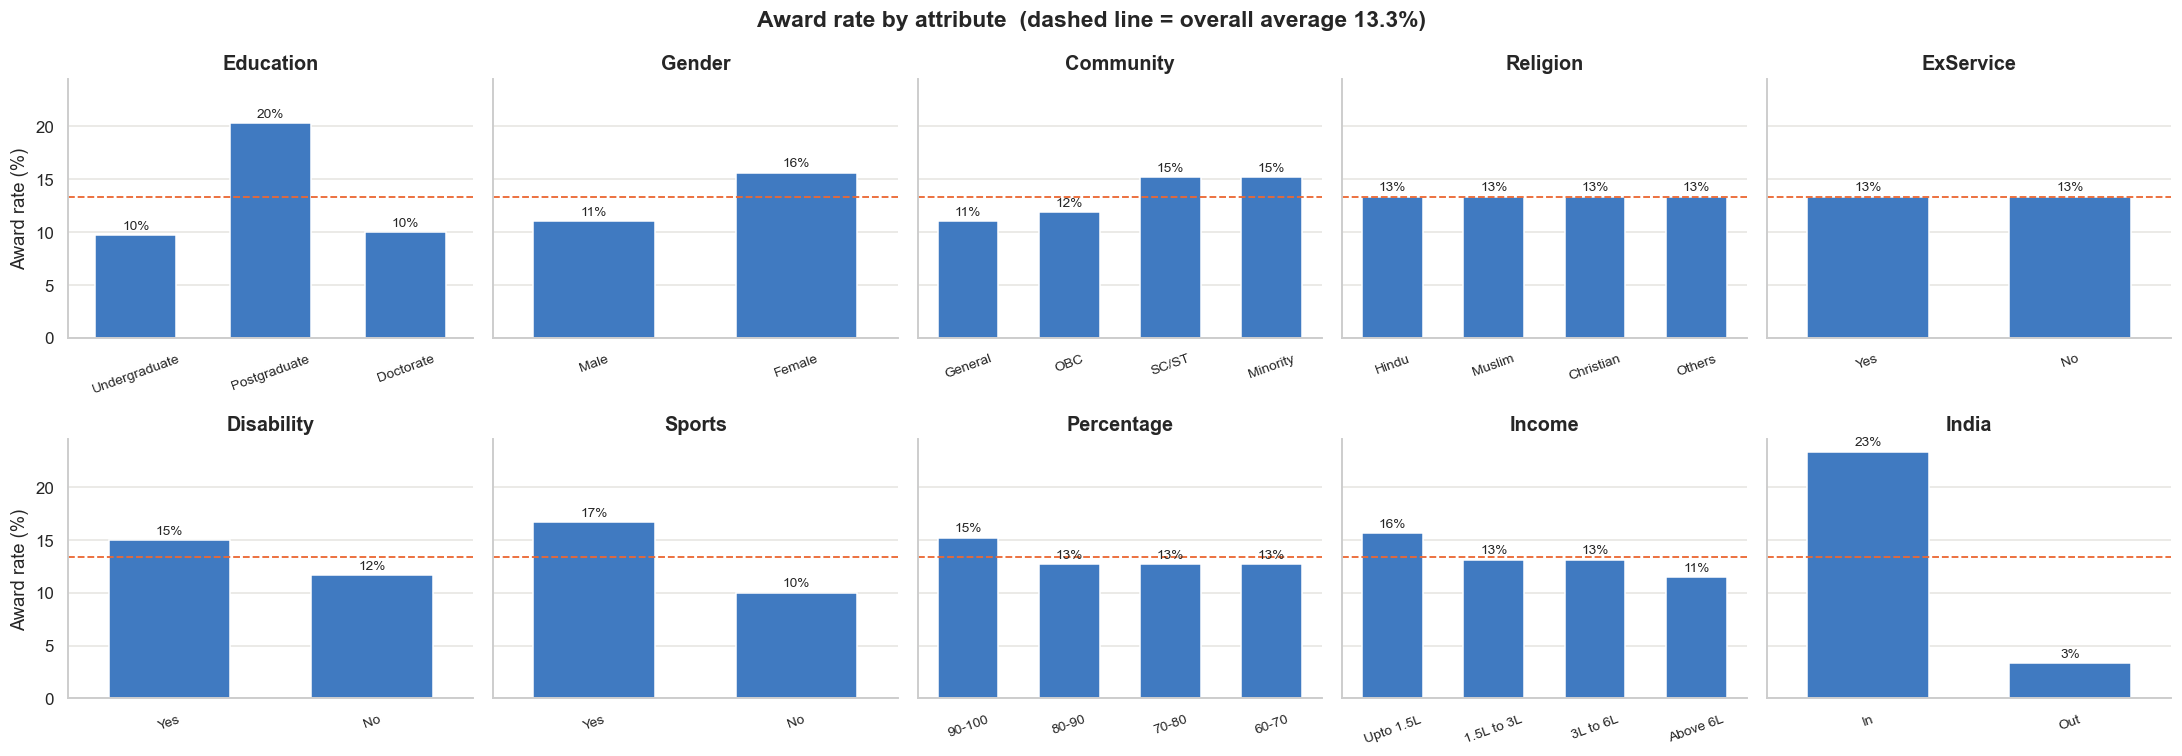

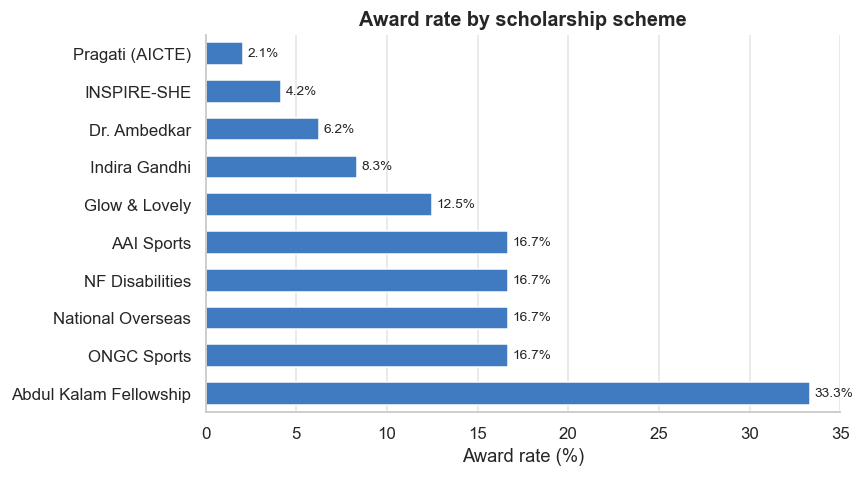

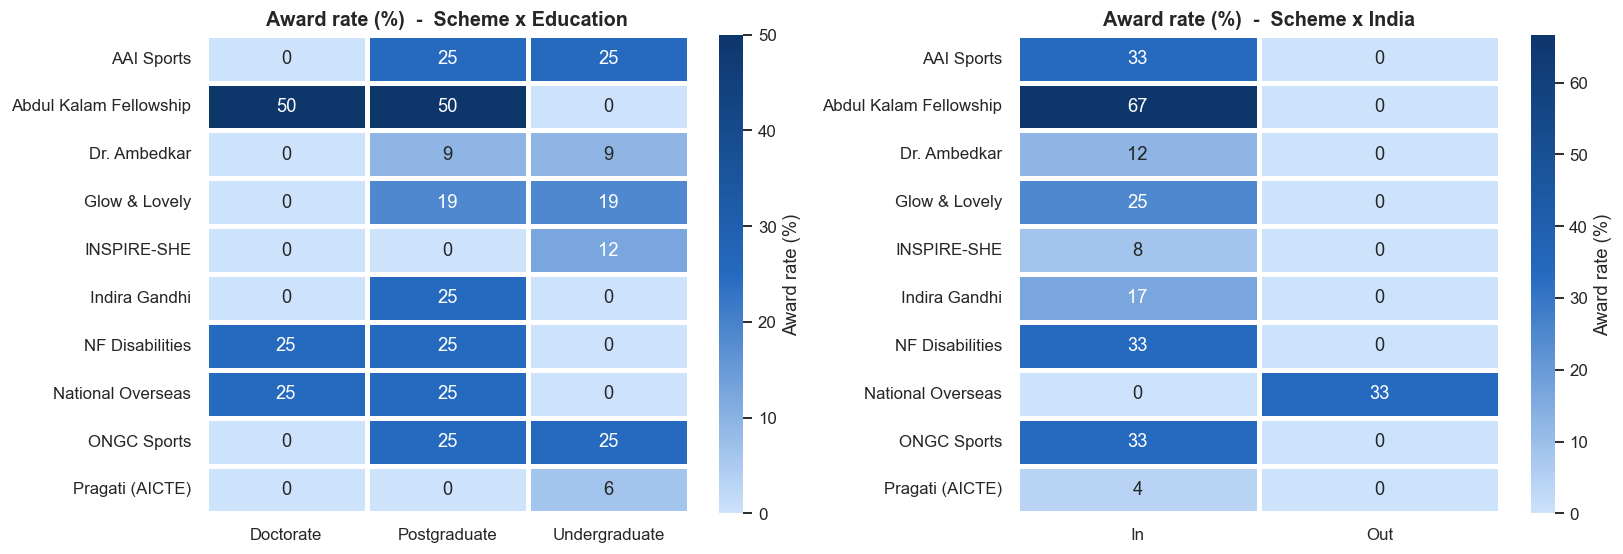

In [10]:
d = df.assign(Awarded=df.Outcome * 100)

# (a) award rate by each attribute
attrs = [c for c in df.columns if c not in ('Outcome', 'Scheme')]
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharey=True)
for ax, c in zip(axes.ravel(), attrs):
    sns.barplot(data=d, x=c, y='Awarded', color=BLUE, errorbar=None, width=0.6, ax=ax)
    ax.bar_label(ax.containers[0], fmt='%.0f%%', fontsize=9, padding=2)
    ax.axhline(d.Awarded.mean(), color=ORANGE, lw=1.2, ls='--')      # overall average line
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel('Award rate (%)' if ax in axes[:, 0] else '')
    ax.tick_params(axis='x', rotation=20, labelsize=9)
fig.suptitle('Award rate by attribute  (dashed line = overall average 13.3%)', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

# (b) award rate by scheme
sc = d.groupby('Scheme').Awarded.mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=sc.values, y=sc.index, color=BLUE, width=0.6, ax=ax)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontsize=9)
ax.set_title('Award rate by scholarship scheme'); ax.set_xlabel('Award rate (%)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

# (c) heatmaps: where are awards concentrated?
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, col in zip(axes, ['Education', 'India']):
    pv = d.pivot_table(index='Scheme', columns=col, values='Awarded', aggfunc='mean')
    sns.heatmap(pv, annot=True, fmt='.0f', cmap=SEQ, linewidths=2, linecolor='white', cbar_kws={'label': 'Award rate (%)'}, ax=ax)
    ax.set_title(f'Award rate (%)  -  Scheme x {col}'); ax.set_ylabel(''); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 1.6 Attribute subset selection
Attribute subset selection: remove attributes that have no relation with the Outcome.

In [11]:
# Religion and ExService have V = 0 (no relation with Outcome) -> removed
DROP = ['Religion', 'ExService']
data = df.drop(columns=DROP)
print('Dropped :', DROP)
print('Kept    :', [c for c in data.columns if c != 'Outcome'])

Dropped : ['Religion', 'ExService']
Kept    : ['Scheme', 'Education', 'Gender', 'Community', 'Disability', 'Sports', 'Percentage', 'Income', 'India']


## 1.7 Data transformation (encoding)
Data transformation: convert text values to numbers (one-hot for Decision Tree / kNN, category codes for Naive Bayes).

In [12]:
X_raw = data.drop(columns='Outcome')
y = data['Outcome'].values
X_onehot = pd.get_dummies(X_raw).astype(np.uint8)                       # for Decision Tree / kNN
X_codes  = X_raw.apply(lambda s: s.astype('category').cat.codes)         # for Naive Bayes
print('One-hot shape :', X_onehot.shape)
X_onehot.head(3)

One-hot shape : (245760, 33)


,Scheme_AAI Sports,Scheme_Abdul Kalam Fellowship,Scheme_Dr. Ambedkar,Scheme_Glow & Lovely,Scheme_INSPIRE-SHE,Scheme_Indira Gandhi,Scheme_NF Disabilities,Scheme_National Overseas,Scheme_ONGC Sports,Scheme_Pragati (AICTE),...,Percentage_60-70,Percentage_70-80,Percentage_80-90,Percentage_90-100,Income_1.5L to 3L,Income_3L to 6L,Income_Above 6L,Income_Upto 1.5L,India_In,India_Out
0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0
1,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,1,1,0


## 1.8 Train / test split (70 / 30, stratified)
Split the data into 70% training and 30% testing (stratified, so both parts keep the same Awarded %).

In [13]:
idx = np.arange(len(data))
tr, te = train_test_split(idx, test_size=0.30, random_state=42, stratify=y)
print(f'Train: {len(tr)} rows | Test: {len(te)} rows | Awarded in test: {y[te].mean():.1%}')

Train: 172032 rows | Test: 73728 rows | Awarded in test: 13.3%


---
# PART 2: Classification

## 2.0 Evaluation helper
A helper function that stores accuracy, error rate, recall, specificity, precision, F-score and the confusion matrix for every model.

In [14]:
results = {}
def evaluate(name, y_pred):
    tn, fp, fn, tp = confusion_matrix(y[te], y_pred).ravel()
    sens = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if tp + fp else 0
    f1 = 2 * prec * sens / (prec + sens) if prec + sens else 0
    results[name] = {'Accuracy': (tp + tn) / len(te), 'Error rate': (fp + fn) / len(te),
                     'Sensitivity(Recall)': sens, 'Specificity': spec, 'Precision': prec, 'F-score': f1,
                     'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn}

## 2.1 Decision Tree (entropy / information gain)
Decision Tree (scikit-learn) using entropy / information gain.

In [15]:
dt = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=20, random_state=42)
dt.fit(X_onehot.iloc[tr], y[tr])
evaluate('Decision Tree', dt.predict(X_onehot.iloc[te]))

## 2.2 Naive Bayes
Naive Bayes classifier.

In [16]:
nb = CategoricalNB().fit(X_codes.iloc[tr], y[tr])
evaluate('Naive Bayes', nb.predict(X_codes.iloc[te]))

## 2.3 k-Nearest Neighbour (k = 5, 20k training rows for speed)
k-Nearest Neighbour classifier (k = 5). Uses 20,000 training rows to keep it fast.

In [17]:
sub = tr[:20000]
knn = KNeighborsClassifier(n_neighbors=5).fit(X_onehot.iloc[sub], y[sub])
evaluate('kNN (k=5)', knn.predict(X_onehot.iloc[te]))

## 2.4 Decision Tree FROM SCRATCH (ID3, entropy)
Decision Tree **written from scratch** (ID3 algorithm: choose the attribute with the highest information gain at every step).

In [19]:
def entropy(labels):
    p = np.bincount(labels, minlength=2) / len(labels)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def info_gain(X, labels, col):
    total, gain = entropy(labels), 0.0
    for _, g in X.groupby(col, observed=True).groups.items():
        gain += len(g) / len(labels) * entropy(labels[X.index.get_indexer(g)])
    return total - gain

def build_id3(X, labels, attrs, depth=0, max_depth=10):
    if len(set(labels)) == 1:                         # pure node -> leaf
        return int(labels[0])
    if not attrs or depth == max_depth:               # nothing left to split -> majority class
        return int(np.bincount(labels).argmax())
    best = max(attrs, key=lambda a: info_gain(X, labels, a))
    node = {'attr': best, 'majority': int(np.bincount(labels).argmax()), 'children': {}}
    for val, g in X.groupby(best, observed=True).groups.items():
        pos = X.index.get_indexer(g)
        node['children'][val] = build_id3(X.iloc[pos], labels[pos], [a for a in attrs if a != best], depth + 1, max_depth)
    return node

def predict_id3(node, row):
    while isinstance(node, dict):
        node = node['children'].get(row[node['attr']], node['majority'])
    return node

Xtr_raw = X_raw.iloc[tr].reset_index(drop=True)
tree = build_id3(Xtr_raw, y[tr], list(Xtr_raw.columns))
pred_id3 = [predict_id3(tree, r) for _, r in X_raw.iloc[te].iterrows()]
evaluate('ID3 (from scratch)', np.array(pred_id3))
print('Root attribute chosen by ID3 (highest information gain):', tree['attr'])

Root attribute chosen by ID3 (highest information gain): India


## 2.5 Compare all models
Comparison table and chart of all four models.

                    Accuracy  Error rate  Sensitivity(Recall)  Specificity  Precision  F-score
Decision Tree         0.9998      0.0002               1.0000       0.9997     0.9983   0.9991
Naive Bayes           0.8832      0.1168               0.1725       0.9925     0.7798   0.2825
kNN (k=5)             0.9566      0.0434               0.7231       0.9925     0.9366   0.8161
ID3 (from scratch)    1.0000      0.0000               1.0000       1.0000     1.0000   1.0000


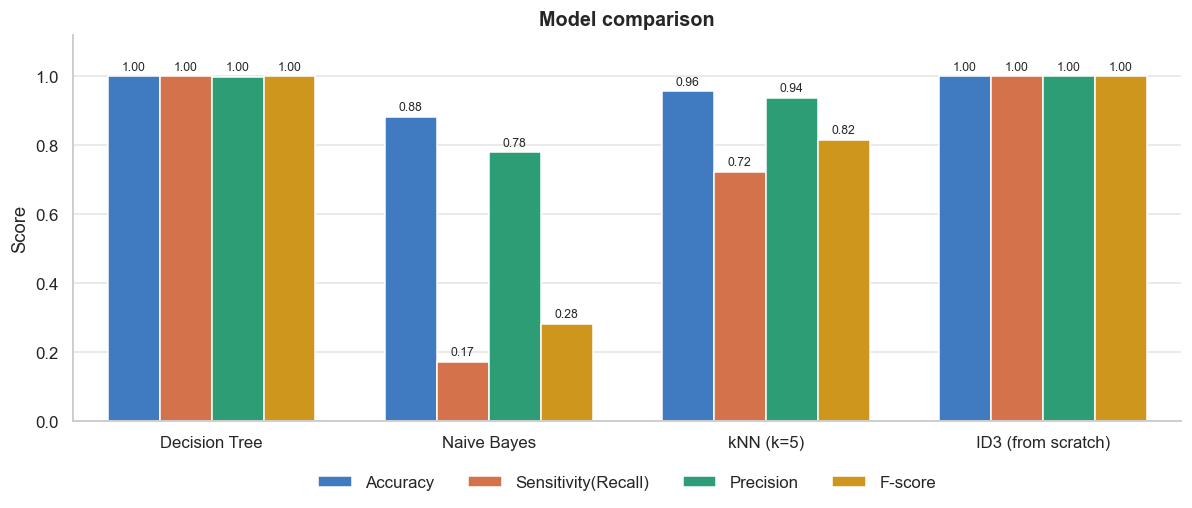

In [20]:
table = pd.DataFrame(results).T
print(table[['Accuracy', 'Error rate', 'Sensitivity(Recall)', 'Specificity', 'Precision', 'F-score']].round(4).to_string())
m = table[['Accuracy', 'Sensitivity(Recall)', 'Precision', 'F-score']].astype(float).reset_index(names='Model') \
        .melt(id_vars='Model', var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(data=m, x='Model', y='Score', hue='Metric', palette=[BLUE, ORANGE, AQUA, YELLOW], width=0.75, ax=ax)
ax.set_ylim(0, 1.12); ax.set_title('Model comparison'); ax.set_xlabel('')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8, padding=2)
plt.tight_layout(); plt.show()

## 2.6 Confusion matrix (best model: Decision Tree)
Confusion matrices: how many Awarded / Rejected students were predicted correctly.

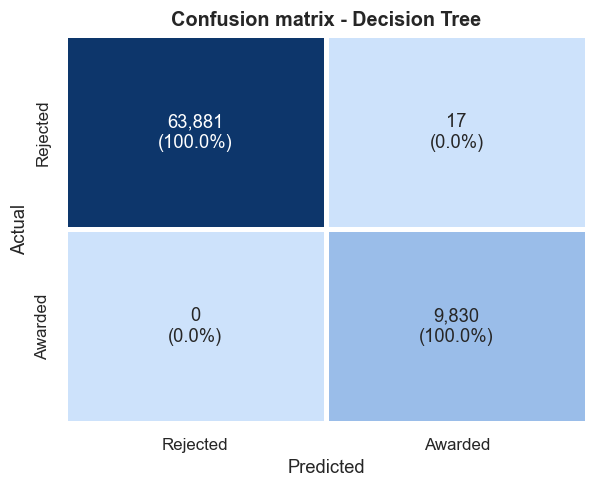

In [21]:
cm = confusion_matrix(y[te], dt.predict(X_onehot.iloc[te]))
labels = np.array([[f'{v:,}\n({v / cm[i].sum():.1%})' for v in row] for i, row in enumerate(cm)])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(cm, annot=labels, fmt='', cmap=SEQ, cbar=False, linewidths=3, linecolor='white',
            xticklabels=['Rejected', 'Awarded'], yticklabels=['Rejected', 'Awarded'], annot_kws={'fontsize': 12}, ax=ax)
ax.set_title('Confusion matrix - Decision Tree'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 2.7 Which attributes matter? (information gain)
The 10 features that the Decision Tree uses most.

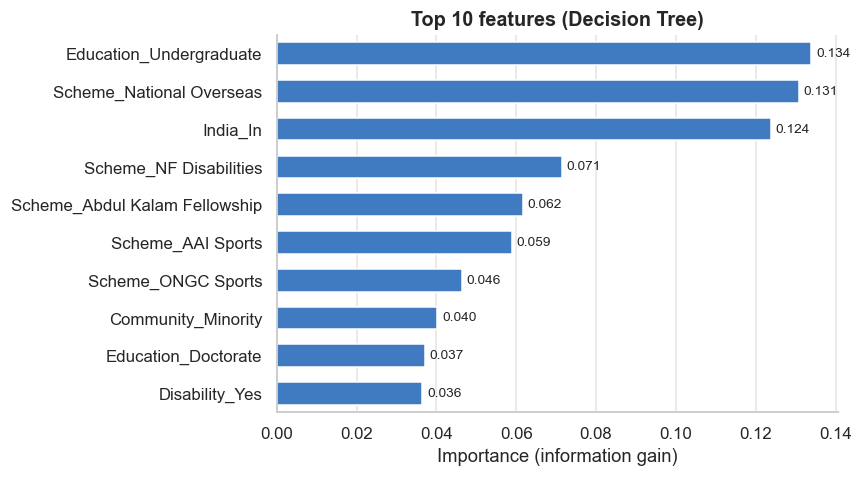

In [22]:
imp = pd.Series(dt.feature_importances_, index=X_onehot.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=imp.values, y=imp.index, color=BLUE, width=0.6, ax=ax)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Top 10 features (Decision Tree)'); ax.set_xlabel('Importance (information gain)'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

## 2.8 Decision Tree diagram
The Decision Tree drawn as a diagram (blue = Awarded, orange = Rejected). Also saved as `decision_tree.png`.

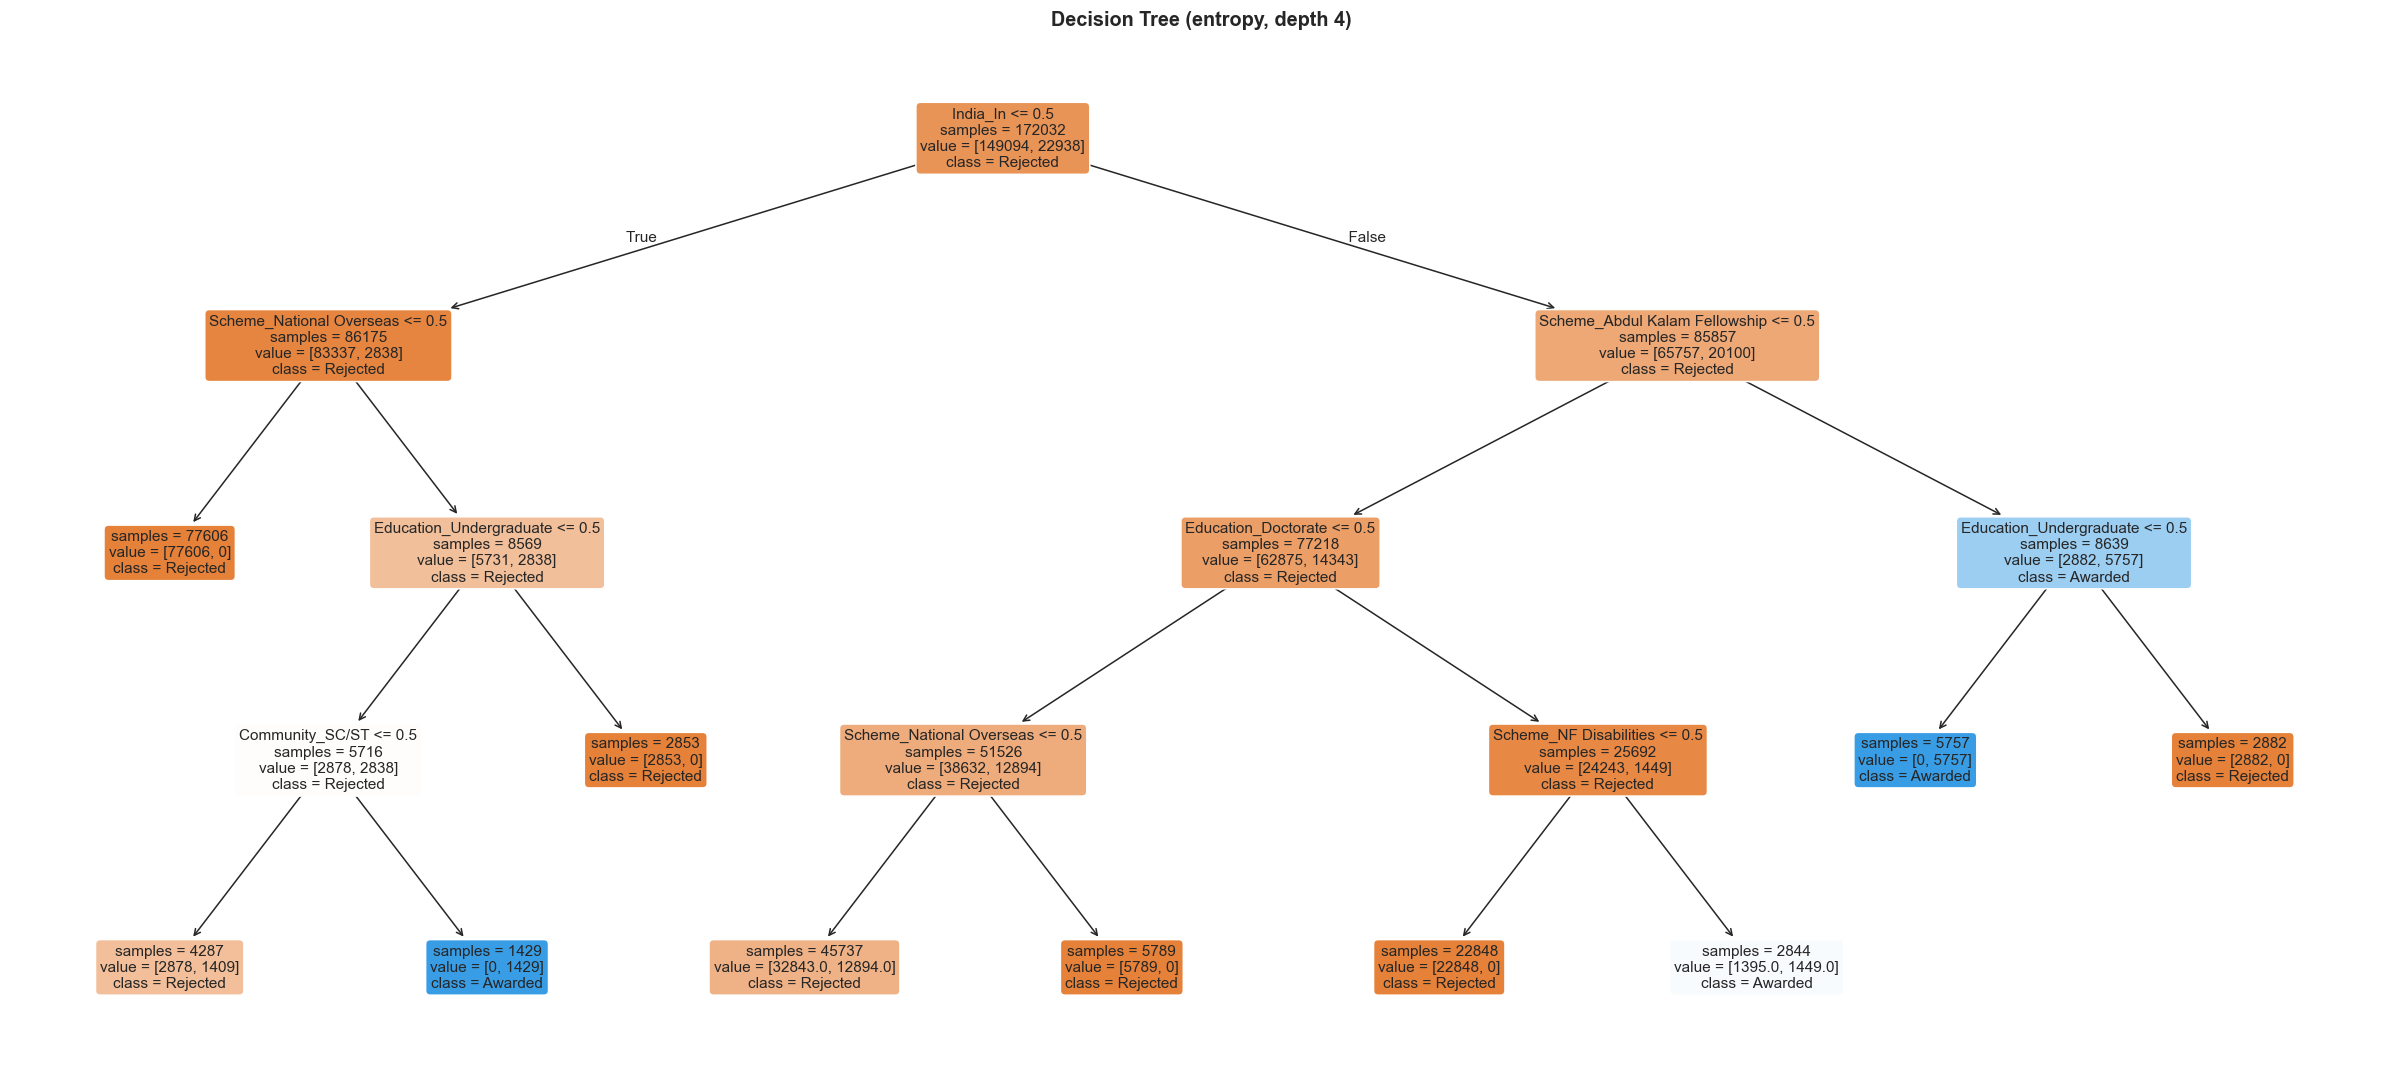

In [23]:
small = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42).fit(X_onehot.iloc[tr], y[tr])
plt.figure(figsize=(22, 10))
plot_tree(small, feature_names=list(X_onehot.columns), class_names=['Rejected', 'Awarded'],
          filled=True, rounded=True, fontsize=10, impurity=False)
plt.title('Decision Tree (entropy, depth 4)'); plt.tight_layout()
plt.savefig('decision_tree.png', dpi=150); plt.show()

## 2.9 Predict for a new student
Predict for a new student: enter the details and get Awarded / Rejected with a probability.

In [24]:
def predict_student(**s):
    """Example: predict_student(Scheme='Abdul Kalam Fellowship', Education='Postgraduate', Gender='Female',
       Community='General', Disability='No', Sports='No', Percentage='80-90', Income='Upto 1.5L', India='In')"""
    row = pd.get_dummies(pd.DataFrame([s])).reindex(columns=X_onehot.columns, fill_value=0)
    p = dt.predict_proba(row)[0, 1]
    print(f"Prediction: {'AWARDED' if p >= 0.5 else 'REJECTED'}  (probability of award = {p:.2f})")

predict_student(Scheme='Abdul Kalam Fellowship', Education='Postgraduate', Gender='Female', Community='General',
                Disability='No', Sports='No', Percentage='80-90', Income='Upto 1.5L', India='In')
predict_student(Scheme='National Overseas', Education='Undergraduate', Gender='Male', Community='OBC',
                Disability='No', Sports='No', Percentage='70-80', Income='3L to 6L', India='Out')

Prediction: AWARDED  (probability of award = 1.00)
Prediction: REJECTED  (probability of award = 0.00)
